# Forecasting San Francisco Parking Meter Payment Activity

**DATA 245 group project**  
Jietian Chen, Eric Zhao, Alaa Ahmed, Tramy Nguyen

**Question:** Can classical machine learning forecast next-hour meter payment activity better than simple historical baselines?

The proposal originally discussed parking availability. Transactions do not supply occupancy ground truth. The implemented target is **new paid-session starts per eligible single-space meter**, classified using training-only terciles. High activity can reflect rapid turnover and must not be equated with few vacant spaces.

All displayed numbers come from the committed public DataSF observations and the executable Python pipeline. No synthetic observations or invented experiment results are used.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import joblib
from IPython.display import display, Image

ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'src/train.py').exists())
sys.path.insert(0, str(ROOT))
pd.set_option('display.max_columns', 20)
print('Project root:', ROOT)


Project root: /Users/maisu/Documents/SJSU/Data 245 Machine Learning/Project/parking-pressure


## 1. Sources and sampling

- [DataSF detailed revenue transactions](https://data.sfgov.org/d/imvp-dq3v): NS = new session, AT = additional time, SC = status change.
- [DataSF parking meter inventory](https://data.sfgov.org/d/8vzz-qzz9): POST_ID joins transactions to blockfaces.
- Fixed observation period: September 1 through October 31, 2026.
- Inventory-only seed-245 sample: 16 neighborhoods, one eligible blockface each. Grey, single-space, active M/T, SFMTA on-street meters, 12–35 spaces per blockface.
- The snapshot is later than the payment period. Meter inventory changes and source coverage are limitations.
- Published timestamps have no timezone offset. We retain those values without claiming verified local-time alignment.

The aggregate CSV and exact API query manifest are included. Full inventory and per-query caches are excluded from Git to keep the repository compact.

In [2]:
manifest = json.loads((ROOT / 'data/raw/download_manifest.json').read_text())
display(pd.Series({k: manifest[k] for k in ['start_inclusive','end_exclusive','inventory_rows',
    'selected_meters','selected_blockfaces','source_event_count']}))
coverage = pd.read_csv(ROOT / 'results/block_coverage.csv', dtype={'blockface_id': str})
display(coverage[['blockface_id','neighborhood','supply','reporting_meters',
                  'reporting_meter_fraction','modeling_rows']])


start_inclusive        2026-09-01
end_exclusive          2026-11-01
inventory_rows              38847
selected_meters               233
selected_blockfaces            16
source_event_count          27579
dtype: object

,blockface_id,neighborhood,supply,reporting_meters,reporting_meter_fraction,modeling_rows
0,108031,Inner Richmond,12,12.0,1.000000,400
1,321352,Outer Richmond,12,8.0,0.666667,380
2,336122,Nob Hill,12,12.0,1.000000,400
3,440191,Western Addition,21,18.0,0.857143,400
4,462132,Haight Ashbury,19,15.0,0.789474,400
5,471102,South of Market,19,0.0,0.000000,0
6,491161,Bayview Hunters Point,13,0.0,0.000000,0
7,545011,Visitacion Valley,12,12.0,1.000000,400
8,568311,Bernal Heights,12,0.0,0.000000,0
9,568451,Excelsior,13,12.0,0.923077,400


## 2. Forecast definition and leakage controls

At the start of hour H, predict the activity class during [H, H+1). Calendar and location are known. Payment-derived inputs use H−1, H−2, H−24, H−168, and a three-hour trailing mean ending at H−1.

`target_pressure = NS starts in H / eligible single-space meters from the inventory snapshot`.

Classes use the training-only 1/3 and 2/3 quantiles. This rate is an activity intensity, **not an occupancy probability** and is not constrained to [0, 1]. All-day-silent blockfaces/dates receive missing status; within covered block-days, unrecorded hourly events receive zero. Coverage filtering is retrospective and cannot distinguish free parking from data outages.

The analytical window is published hours 09:00–18:59, Monday–Saturday. It does not establish actual charging schedules. Rows with missing target/history are excluded. Dates split approximately 60/20/20, with every blockface at the same timestamp in the same partition. The scaler and encoder fit on training data during tuning.

In [3]:
quality = json.loads((ROOT / 'results/data_quality.json').read_text())
display(pd.DataFrame(quality['split_summary']).T)
print('Training-only class boundaries:', quality['thresholds_training_only'])
print('Sampled / modeled blockfaces:', quality['sampled_blockfaces'], '/', quality['modeled_blockfaces'])
data = pd.read_csv(ROOT / 'data/processed/modeling_data.csv', dtype={'blockface_id': str})
display(data[['target_start','blockface_id','supply','pressure_lag1',
              'pressure_lag24','pressure_lag168','target_pressure','target_class','split']].head())


,rows,dates,start,end,class_counts
train,2820,24,2026-09-08T09:00:00,2026-10-09T18:00:00,"{'0': 950, '1': 1116, '2': 754}"
validation,930,8,2026-10-10T09:00:00,2026-10-21T18:00:00,"{'0': 309, '1': 397, '2': 224}"
test,920,8,2026-10-22T09:00:00,2026-10-31T18:00:00,"{'0': 283, '1': 376, '2': 261}"


Training-only class boundaries: [0.10526315789473684, 0.3333333333333333]
Sampled / modeled blockfaces: 16 / 12


,target_start,blockface_id,supply,pressure_lag1,pressure_lag24,pressure_lag168,target_pressure,target_class,split
0,2026-09-08 09:00:00,108031,12,0.000000,0.000000,0.333333,0.333333,1,train
1,2026-09-08 09:00:00,321352,12,0.000000,0.166667,0.166667,0.083333,0,train
2,2026-09-08 09:00:00,336122,12,0.166667,0.333333,0.666667,0.583333,2,train
3,2026-09-08 09:00:00,440191,21,0.000000,0.047619,0.000000,0.000000,0,train
4,2026-09-08 09:00:00,462132,19,0.052632,0.105263,0.157895,0.421053,2,train


## 3. Exploratory analysis

The following charts summarize the final usable observations. Coverage and historical-feature requirements remove observations, so these patterns describe the analyzed sample rather than the entire city.

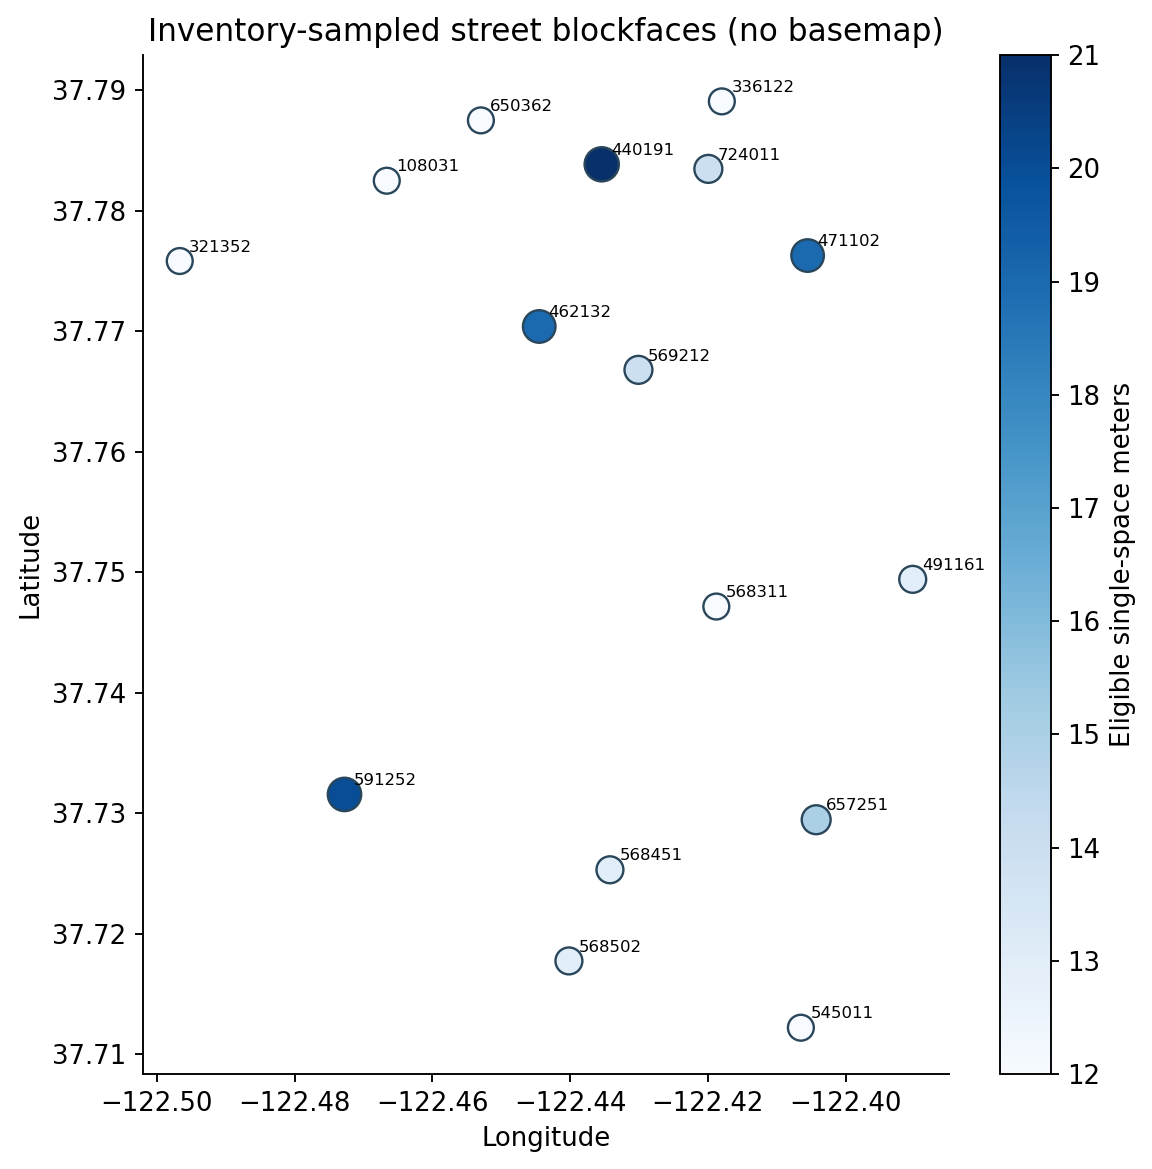

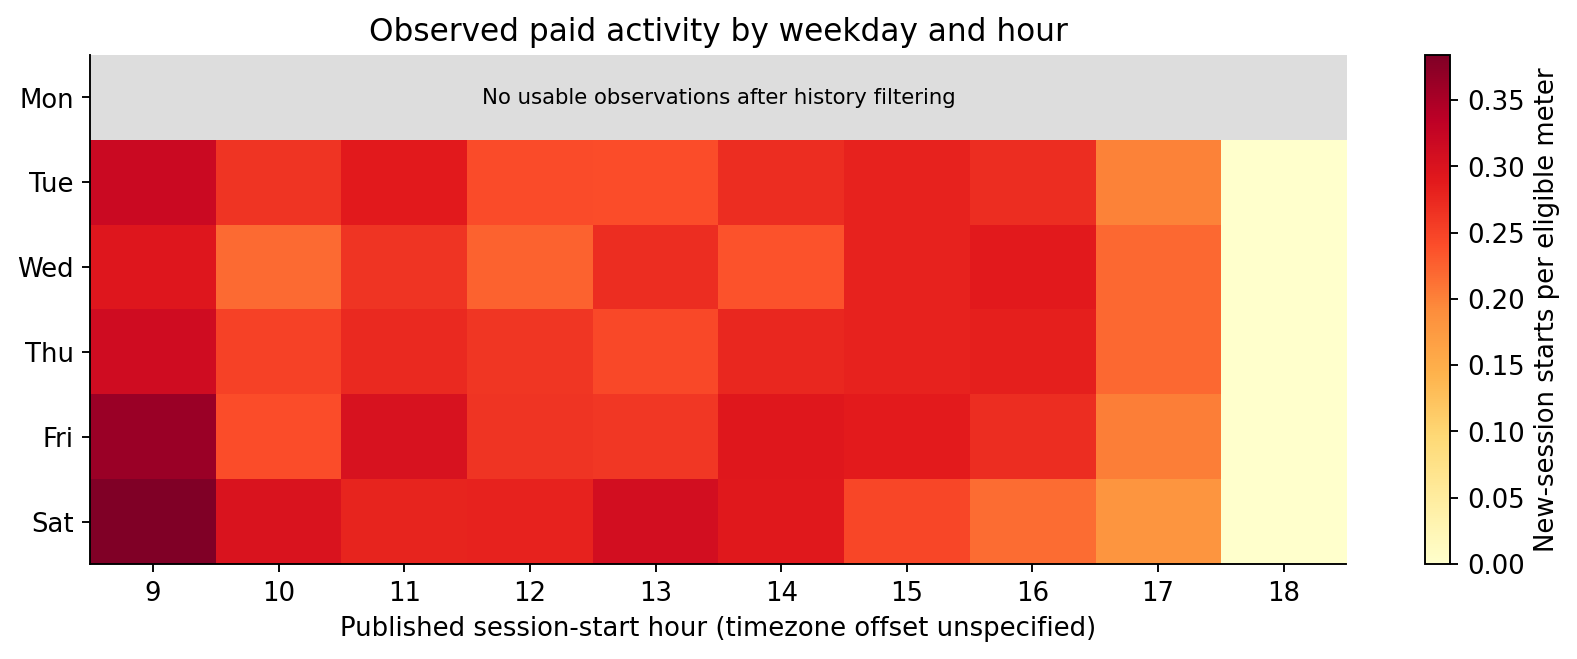

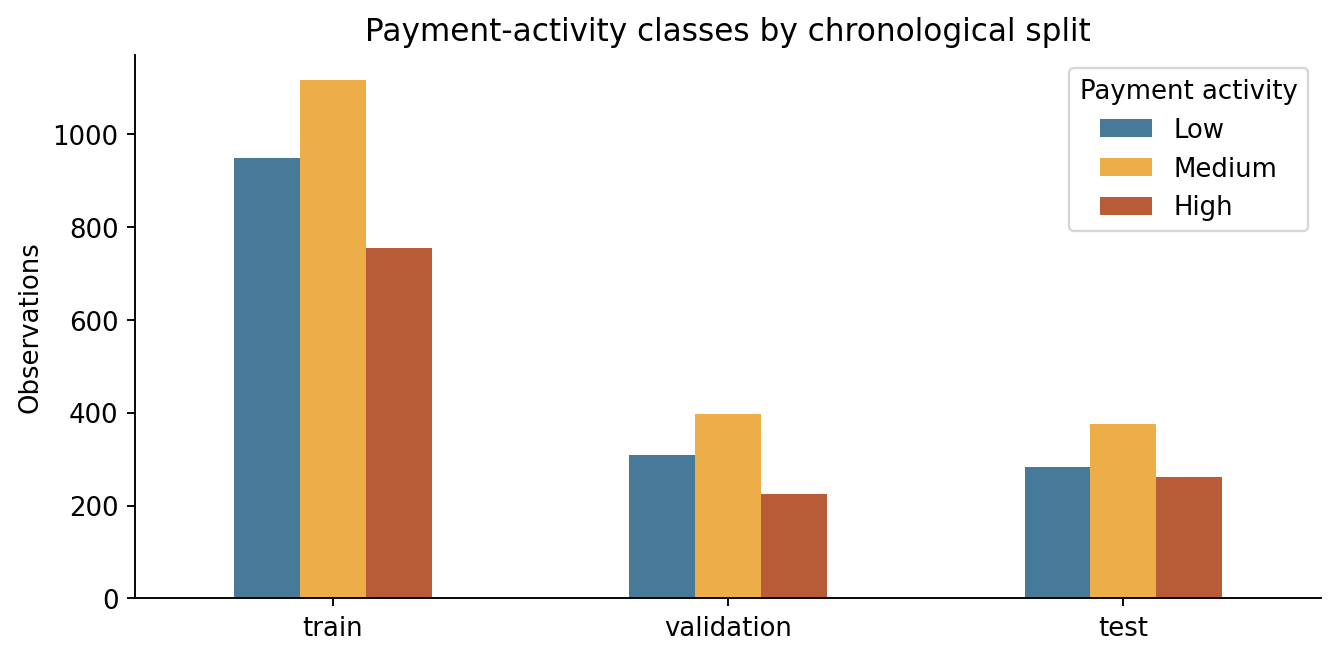

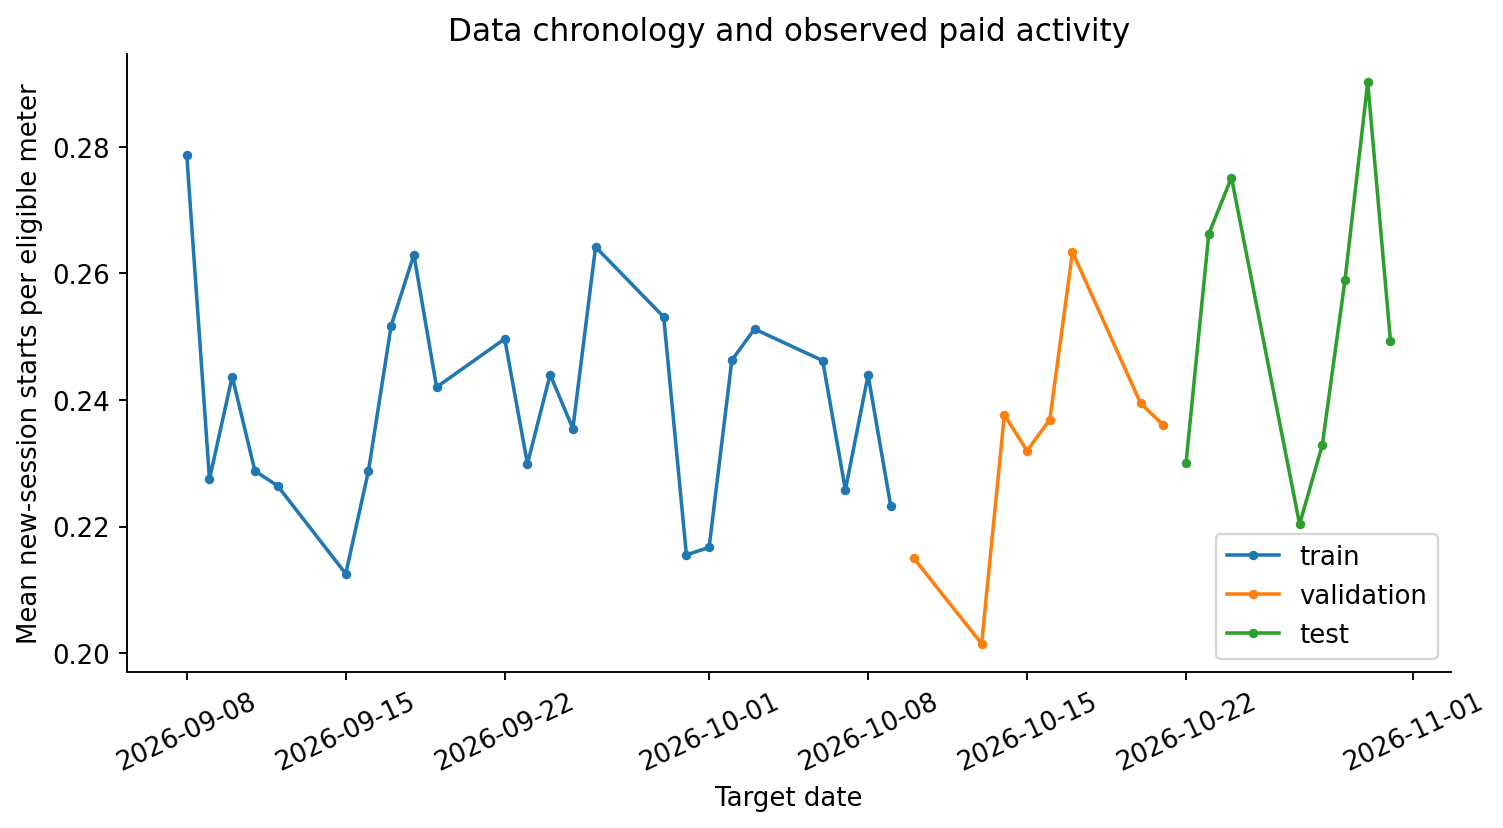

In [4]:
for name in ['sampled_locations','weekday_hour_heatmap','class_distribution','chronological_split']:
    display(Image(filename=str(ROOT / f'results/figures/{name}.png'), width=850))


## 4. Reproducible training

`src/train.py` implements the complete workflow. It compares Logistic Regression, KNN, Decision Tree, and Random Forest, three configurations each. Validation macro F1 selects each configuration and the final machine-learning algorithm. Each selected configuration then fits train + validation and receives one chronological test evaluation. Majority, persistence, and blockface/weekday/hour seasonal baselines provide reference points.

Set the switch below to `True` to regenerate all results. The default reuses the completed experiment, keeping a quick notebook walkthrough fast. To redownload source data, separately run `python src/download_data.py` from the repository root.

In [5]:
RUN_TRAINING = False
if RUN_TRAINING:
    from src.train import main as train_project
    train_project()
else:
    print('Using committed experiment outputs. Set RUN_TRAINING=True to rerun.')


Using committed experiment outputs. Set RUN_TRAINING=True to rerun.


,model,parameters,validation_macro_f1
8,Decision Tree,"DecisionTreeClassifier(max_depth=12, min_sampl...",0.638510
7,Decision Tree,"DecisionTreeClassifier(max_depth=8, min_sample...",0.634763
6,Decision Tree,"DecisionTreeClassifier(max_depth=4, min_sample...",0.627021
4,KNN,"KNeighborsClassifier(n_neighbors=21, weights='...",0.656333
5,KNN,"KNeighborsClassifier(n_neighbors=51, weights='...",0.647275
3,KNN,"KNeighborsClassifier(n_neighbors=7, weights='d...",0.611244
2,Logistic Regression,"LogisticRegression(C=10, max_iter=1500, random...",0.650479
1,Logistic Regression,"LogisticRegression(C=1, max_iter=1500, random_...",0.650290
0,Logistic Regression,"LogisticRegression(C=0.1, max_iter=1500, rando...",0.647330
11,Random Forest,"RandomForestClassifier(min_samples_leaf=8, n_e...",0.655979


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,quadratic_kappa,high_activity_recall,log_loss,roc_auc_ovr_macro,validation_macro_f1,fit_macro_f1,fit_seconds,test_prediction_seconds
0,Seasonal baseline,0.6783,0.6702,0.7160,0.6702,0.6835,0.6830,0.5104,0.6642,0.6130,NaN,NaN,NaN,NaN,NaN,NaN
1,Random Forest,0.6826,0.6666,0.7291,0.6666,0.6832,0.6846,0.5188,0.6731,0.5402,0.7006,0.8354,0.6560,0.7415,0.2500,0.0157
2,KNN,0.6696,0.6578,0.7039,0.6578,0.6719,0.6721,0.4958,0.6720,0.5326,0.8759,0.8245,0.6563,0.9995,0.0038,0.1187
3,Logistic Regression,0.6620,0.6548,0.6815,0.6548,0.6643,0.6636,0.4827,0.6552,0.5441,0.7515,0.8214,0.6505,0.6661,0.2440,0.0033
4,Decision Tree,0.6359,0.6264,0.6526,0.6264,0.6353,0.6368,0.4422,0.5946,0.4943,1.1878,0.7888,0.6385,0.7077,0.0134,0.0019
5,Persistence baseline,0.4848,0.4816,0.4869,0.4816,0.4837,0.4852,0.2140,0.3348,0.4483,NaN,NaN,NaN,NaN,NaN,NaN
6,Majority baseline,0.4087,0.3333,0.1362,0.3333,0.1934,0.2371,0.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN


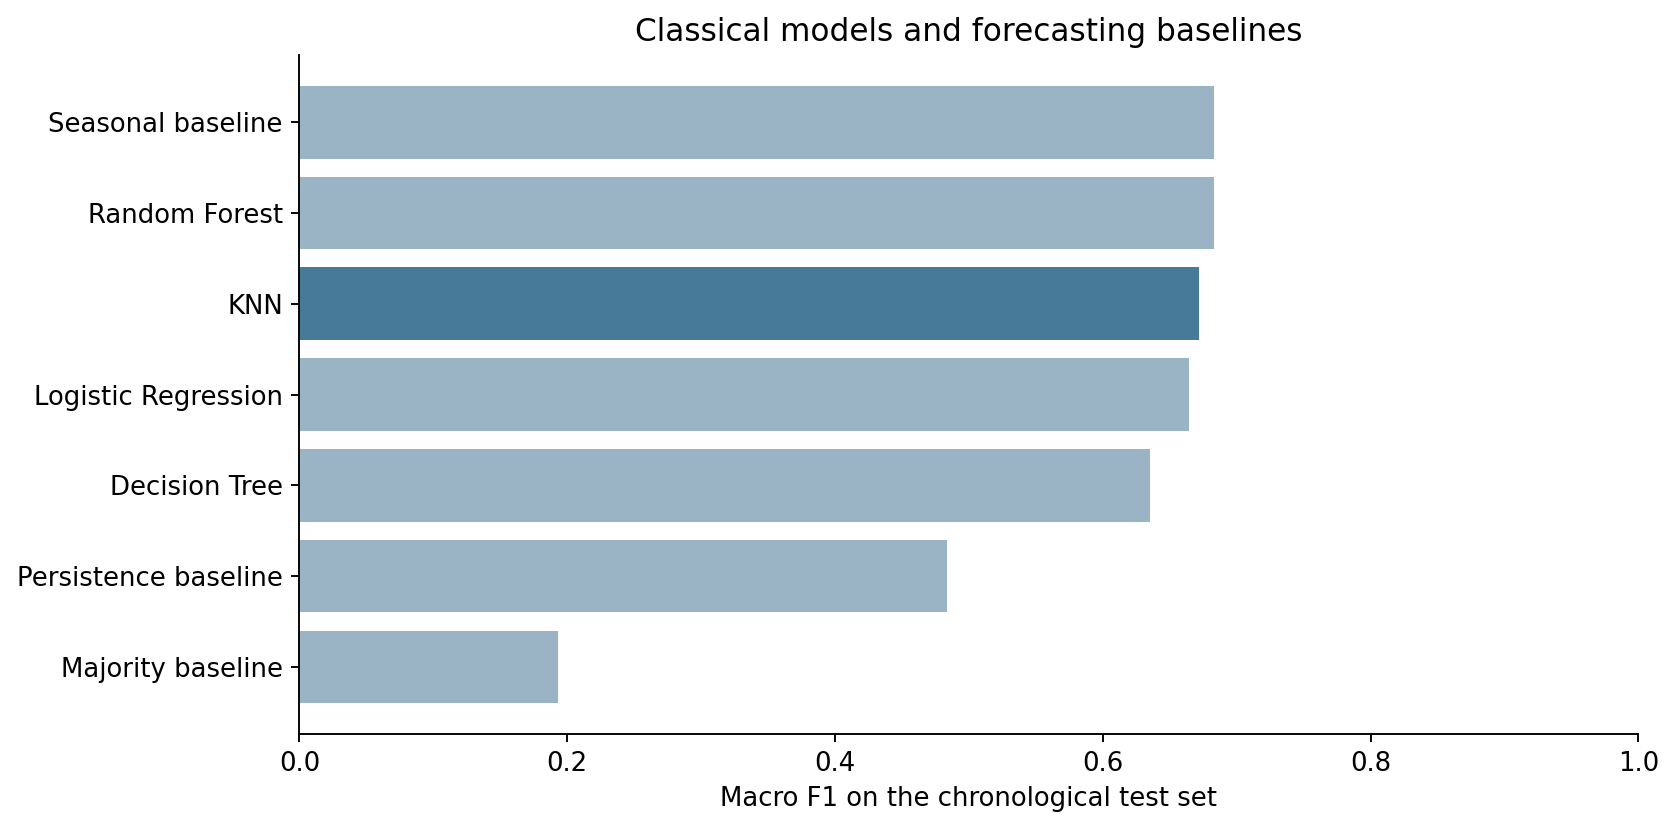

In [6]:
tuning = pd.read_csv(ROOT / 'results/validation_search.csv')
display(tuning.sort_values(['model','validation_macro_f1'], ascending=[True,False]))
metrics = pd.read_csv(ROOT / 'results/test_metrics.csv')
display(metrics.round(4))
display(Image(filename=str(ROOT / 'results/figures/model_comparison.png'), width=900))


## 5. Feature ablation and error analysis

These are descriptive analyses with the already selected hyperparameters. They do not retune the final model against the test set. Adding supply separately to block identity may add little because supply is fixed within a blockface. The random-split diagnostic uses different test observations and cannot isolate leakage or prove that random splitting always increases scores.

,features,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,quadratic_kappa,high_activity_recall
0,Calendar and location,0.6337,0.6304,0.6418,0.6304,0.6344,0.6331,0.4397,0.6166,0.5134
1,"Calendar, location and supply",0.6337,0.6304,0.6418,0.6304,0.6344,0.6331,0.4397,0.6166,0.5134
2,"Calendar, location, supply and history",0.6696,0.6578,0.7039,0.6578,0.6719,0.6721,0.4958,0.6720,0.5326


,dimension,value,rows,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,quadratic_kappa,high_activity_recall
0,blockface_id,108031,80,0.5875,0.5877,0.6816,0.5877,0.6146,0.5766,0.3053,0.5188,0.7632
1,blockface_id,321352,80,0.7000,0.4532,0.4681,0.4532,0.4480,0.6626,0.3578,0.3858,0.0000
2,blockface_id,336122,80,0.6500,0.5560,0.6476,0.5560,0.5757,0.6294,0.3715,0.4424,0.4000
3,blockface_id,440191,80,0.8875,0.6786,0.6267,0.4524,0.4875,0.8644,0.5606,0.4783,0.0000
4,blockface_id,462132,80,0.6500,0.4508,0.5381,0.4508,0.4333,0.5785,0.3698,0.3578,0.0000
5,blockface_id,545011,80,0.6000,0.4729,0.5491,0.4729,0.4611,0.5458,0.2994,0.3625,0.0625
6,blockface_id,568451,80,0.7500,0.5765,0.6392,0.5765,0.5995,0.7314,0.4303,0.6791,0.9091
7,blockface_id,568502,80,0.5500,0.6460,0.6794,0.6460,0.6491,0.5557,0.2669,0.4951,0.4419
8,blockface_id,591252,80,0.6250,0.6231,0.6696,0.6231,0.6417,0.6275,0.3894,0.6104,0.6364
9,blockface_id,650362,80,0.5625,0.5299,0.6779,0.5299,0.5604,0.5596,0.2921,0.5028,0.4231


{
  "comparison": "KNN minus Seasonal baseline, chronological-test macro F1",
  "point_difference": -0.011565292402524241,
  "paired_day_bootstrap_95_percentile_interval": [
    -0.03785561380114122,
    0.01635117509794416
  ],
  "replicates": 1000,
  "test_dates": 8,
  "caveat": "Descriptive interval from few test dates; adjacent dates can remain dependent. Not evidence of citywide or seasonal generalization."
}


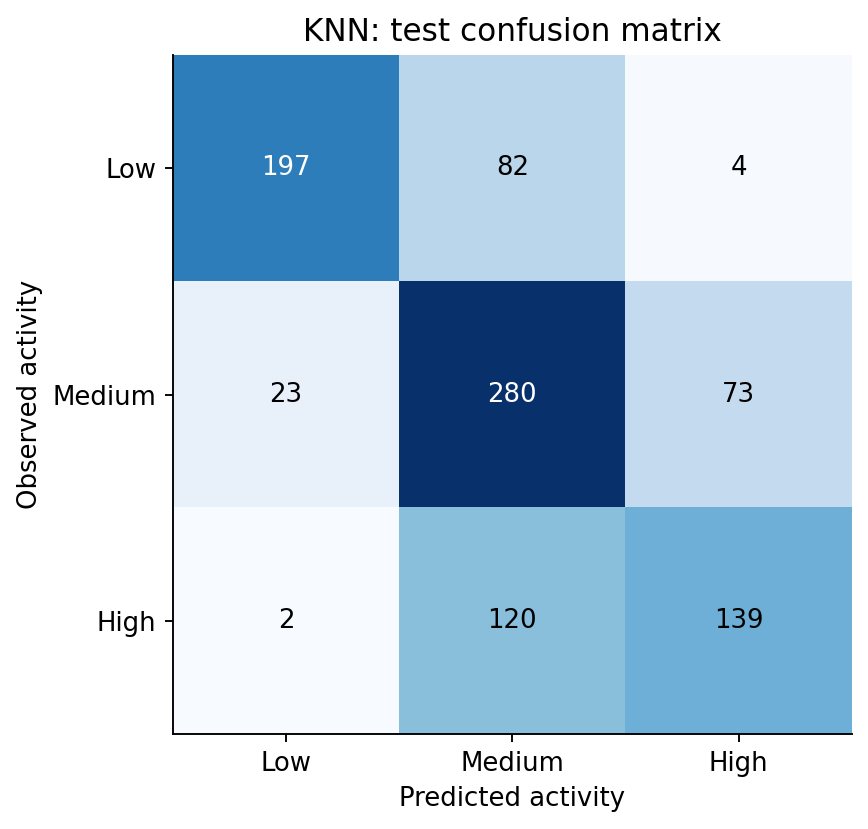

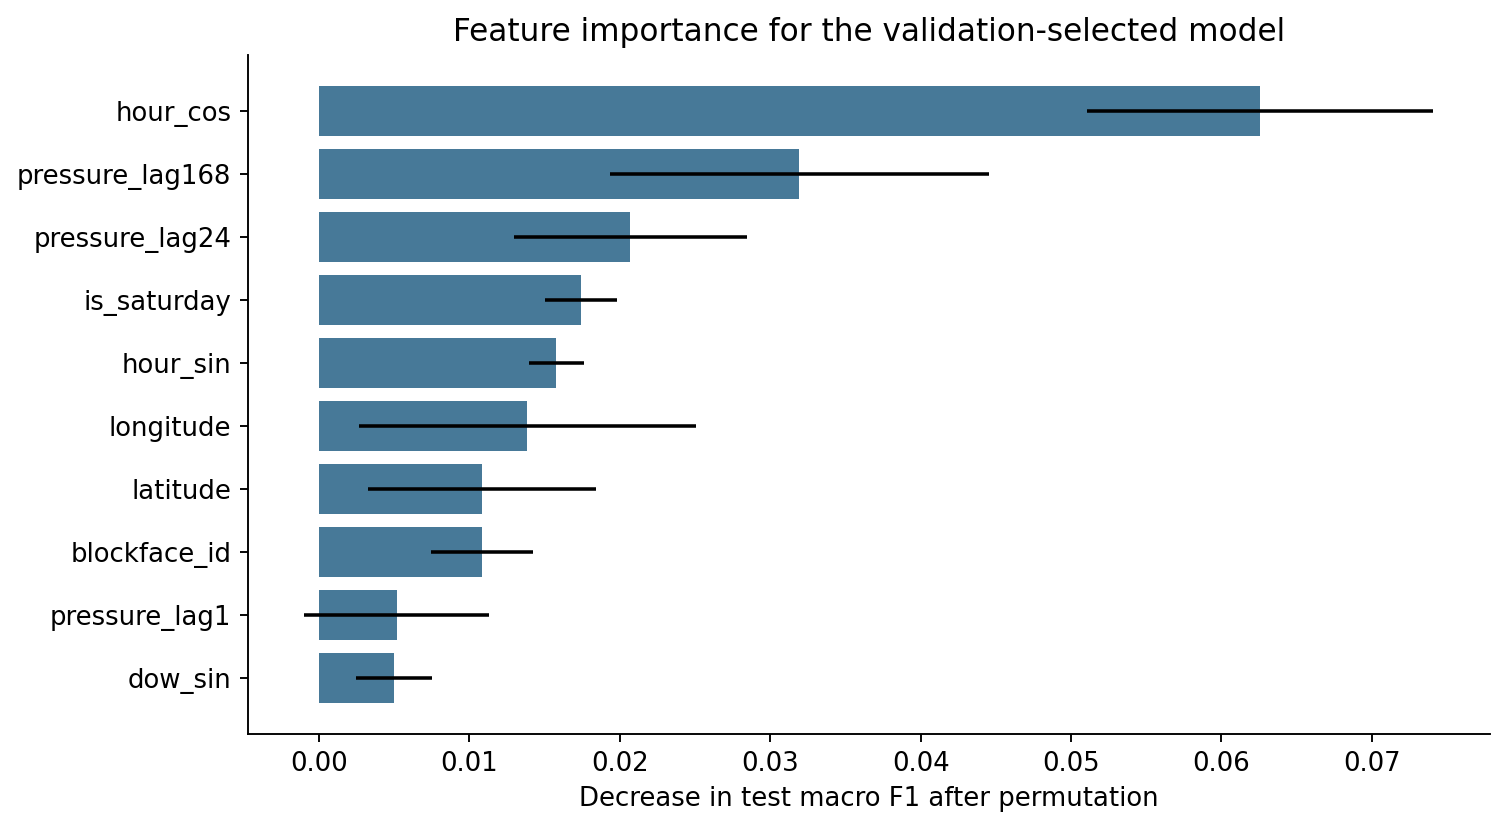

In [7]:
display(pd.read_csv(ROOT / 'results/ablation_metrics.csv').round(4))
display(pd.read_csv(ROOT / 'results/error_analysis.csv').round(4))
uncertainty = json.loads((ROOT / 'results/uncertainty.json').read_text())
print(json.dumps(uncertainty, indent=2))
for name in ['confusion_matrix','feature_importance']:
    display(Image(filename=str(ROOT / f'results/figures/{name}.png'), width=850))


## 6. Saved-model demonstration

This loads the persisted preprocessing pipeline and classifier using actual held-out features. It does not fetch live data, search for vacant parking spaces, or retrain the model. Only load trusted joblib/pickle files.

In [8]:
bundle = joblib.load(ROOT / 'models/parking_activity_model.joblib')
example = pd.read_json(ROOT / 'models/example_input.json', dtype={'blockface_id': str})
predicted = int(bundle['pipeline'].predict(example[bundle['features']])[0])
probabilities = bundle['pipeline'].predict_proba(example[bundle['features']])[0]
print('Validation-selected machine-learning model:', bundle['selected_model'])
print('Prediction:', bundle['class_names'][predicted])
display(pd.Series(probabilities, index=bundle['class_names'], name='Predicted probability'))
print('Saved model bytes:', (ROOT / 'models/parking_activity_model.joblib').stat().st_size)


Validation-selected machine-learning model: KNN
Prediction: High payment activity


Low payment activity       0.129137
Medium payment activity    0.416581
High payment activity      0.454282
Name: Predicted probability, dtype: float64

Saved model bytes: 80097


## 7. Findings and limits

- The seasonal baseline is competitive with the more flexible algorithms. The strongest test macro F1 belongs to the seasonal baseline; the validation-selected ML model is KNN. A claim that ML outperforms the seasonal rule is unsupported.
- Historical inputs improve the selected ML model over its calendar/location-only ablation on this held-out period. This comparison describes the sample, not a causal effect.
- Four originally sampled blockfaces have no events in the period. Twelve blockfaces contribute modeling rows, and some have sparse meter reporting. The inventory denominator does not establish actual operational supply during September–October.
- No Monday rows survive the required 24-hour history after entirely silent Sundays. The final usable sample covers Tuesday–Saturday and does not validate Monday forecasts.
- The test covers eight observed dates. The paired-day bootstrap is descriptive and does not establish citywide or seasonal generalization.
- Paid-session starts cannot validate actual occupancy or parking availability. No measured reduction in congestion, emissions, or cruising is claimed.
- Evaluation uses one-hour rolling forecasts with newly observed preceding-hour activity. Immediate aggregate availability is an assumption; API ingestion latency has not been measured.

For the original proposal and the eventual report, describe the scope refinement explicitly. Ground-truth occupancy or a validated occupancy reconstruction is future work.

## 8. Team and AI disclosure

Team: Jietian Chen, Eric Zhao, Alaa Ahmed, Tramy Nguyen. Individual CRediT roles must reflect work each person actually completes and confirms. See `docs/TEAM_REVIEW.md` for a proposed review division; it is not a record of completed contributions.

OpenAI Codex assisted with implementation, data queries, experiment execution, documentation, and notebook generation. Team members must review and understand the artifacts before submission. No historical scrum meetings or pair-programming sessions are claimed. No leaderboard position is applicable because these are direct city datasets, not competition submissions.